# k-Fold Cross-Validation

This notebook demonstrates `KFold`, `cross_val_score` and `cross_validate` with several metrics, visualises the folds, and studies how the number of folds affects the estimate.

## Import Required Libraries

Import the datasets, model and cross-validation utilities.

In [1]:
# Import the required libraries.
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    KFold, LeaveOneOut, cross_val_score, cross_validate
)

# Define the course colour palette.
colors = ["#179E86", "#2580B7", "#9EBE5B",
          "#C03B26", "#44546A", "#F59B11"]
np.random.seed(42)

## Load the Dataset

Use the breast cancer dataset and a logistic regression model.

In [2]:
# Load the dataset and define the model.
data = load_breast_cancer()
X, y = data.data, data.target
model = LogisticRegression(max_iter=5000)
print(f"Samples: {X.shape[0]}, features: {X.shape[1]}.")

Samples: 569, features: 30.


## Basic k-Fold with cross_val_score

Split the data into 5 folds and average the accuracy across them.

In [3]:
# Evaluate the model with 5-fold cross-validation.
kfold = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(model, X, y, cv=kfold,
                            scoring="accuracy")
print(f"Fold scores: {np.round(cv_scores, 4)}.")
print(f"Mean: {cv_scores.mean():.4f}, "
      f"std: {cv_scores.std():.4f}.")

Fold scores: [0.9561 0.9649 0.9386 0.9737 0.9204].
Mean: 0.9507, std: 0.0191.


## Several Metrics with cross_validate

`cross_validate` reports multiple scoring metrics and the timing for each fold at once.

In [4]:
# Evaluate several metrics simultaneously.
scoring = ["accuracy", "precision", "recall", "f1"]
results = cross_validate(model, X, y, cv=kfold, scoring=scoring)
for metric in scoring:
    values = results[f"test_{metric}"]
    print(f"{metric:>9}: {values.mean():.4f} "
          f"(+/- {values.std():.4f}).")

 accuracy: 0.9507 (+/- 0.0191).
precision: 0.9527 (+/- 0.0231).
   recall: 0.9690 (+/- 0.0171).
       f1: 0.9607 (+/- 0.0165).


## Visualise the Fold Assignment

Draw a diagram where each row is a fold and columns are samples coloured as training or validation.

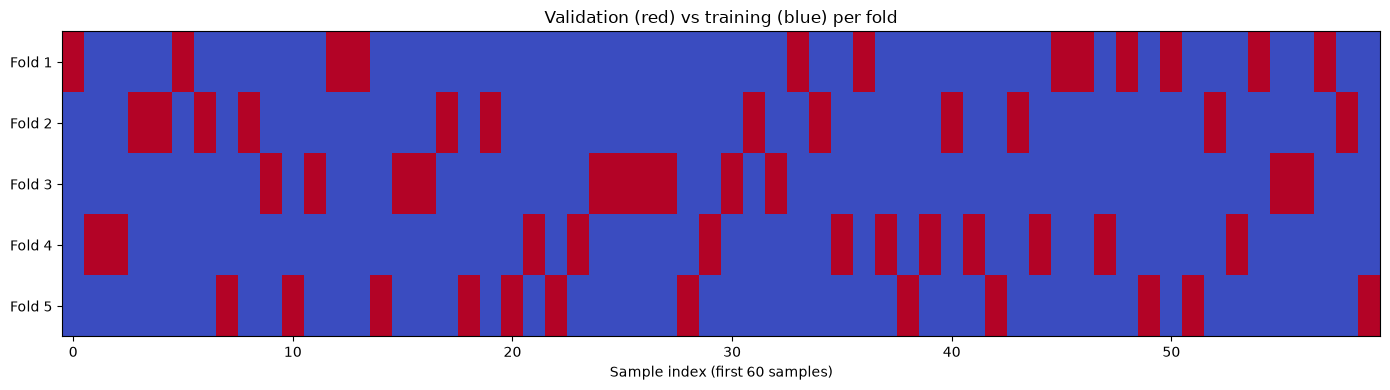

In [5]:
# Build a fold-membership matrix for visualisation.
n_show = 60
viz_kfold = KFold(n_splits=5, shuffle=True, random_state=42)
membership = np.zeros((5, n_show))
for fold, (_, val_idx) in enumerate(
        viz_kfold.split(np.arange(n_show))):
    membership[fold, val_idx] = 1

# Plot the diagram of training vs validation folds.
fig, ax = plt.subplots(figsize=(14, 4))
ax.imshow(membership, aspect="auto", cmap="coolwarm")
ax.set_yticks(range(5))
ax.set_yticklabels([f"Fold {i + 1}" for i in range(5)])
ax.set_xlabel("Sample index (first 60 samples)")
ax.set_title("Validation (red) vs training (blue) per fold")
plt.tight_layout()
plt.show()

## Effect of the Number of Folds

Compare the mean and variance of the estimate for k in {2, 3, 5, 10} and leave-one-out (LOO) on a subsample to keep leave-one-out affordable.

In [6]:
# Use a stratified subsample to keep leave-one-out fast.
from sklearn.model_selection import train_test_split
X_small, _, y_small, _ = train_test_split(
    X, y, train_size=200, random_state=42, stratify=y
)

# Compare several values of k, including leave-one-out.
k_values = [2, 3, 5, 10]
means, stds, labels = [], [], []
for k in k_values:
    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    s = cross_val_score(model, X_small, y_small, cv=kf)
    means.append(s.mean())
    stds.append(s.std())
    labels.append(f"k={k}")

# Add leave-one-out cross-validation.
loo = LeaveOneOut()
loo_scores = cross_val_score(model, X_small, y_small, cv=loo)
means.append(loo_scores.mean())
stds.append(loo_scores.std())
labels.append("LOO")

for lab, m, s in zip(labels, means, stds):
    print(f"{lab:>4}: mean={m:.4f}, std={s:.4f}.")

 k=2: mean=0.9500, std=0.0100.
 k=3: mean=0.9400, std=0.0244.
 k=5: mean=0.9450, std=0.0245.
k=10: mean=0.9550, std=0.0269.
 LOO: mean=0.9550, std=0.2073.


## Plot the Trade-off

As k grows the training sets get larger (less bias) but the fold scores become more variable and costlier to compute.

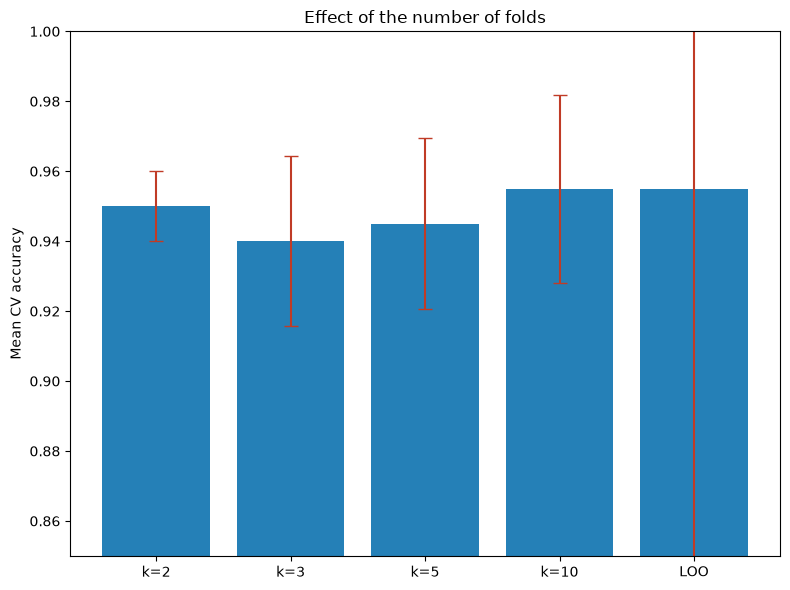

In [7]:
# Plot the mean estimate with its per-fold standard deviation.
fig, ax = plt.subplots(figsize=(8, 6))
positions = np.arange(len(labels))
ax.bar(positions, means, yerr=stds, color=colors[1],
       ecolor=colors[3], capsize=5)
ax.set_xticks(positions)
ax.set_xticklabels(labels)
ax.set_ylim(0.85, 1.0)
ax.set_ylabel("Mean CV accuracy")
ax.set_title("Effect of the number of folds")
plt.tight_layout()
plt.show()

## Summary

- **k-Fold**: partitions the data into k folds, using each fold once for validation and the rest for training.
- **cross_val_score / cross_validate**: return per-fold scores; the latter supports several metrics and timings at once.
- **Choice of k**: larger k reduces bias but increases variance and compute cost; k=5 or k=10 are common defaults.
- **LOO**: uses n-1 samples for training each time, giving a nearly unbiased but high-variance and expensive estimate.